# BTC/USD — high-frequency price + 15-min realised volatility

**Cells**
1. **Config + functions** — edit the `USER CONFIG` block to change anything; everything else adapts automatically.
2. **Fetch + price plot** — pulls Binance 1s klines and Chainlink on-chain rounds, plots price.
3. **Volatility** — calendar-aligned 15-min realised vol from 1s log-returns, annualised.

In [5]:
import time, json, math
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from web3 import Web3

pd.options.display.float_format = "{:.2f}".format

# ╔══════════════════════════════════════════════════════════════════════════╗
# ║                          USER CONFIG                                     ║
# ╚══════════════════════════════════════════════════════════════════════════╝

LOOKBACK_HOURS      = 6          # how far back to fetch price data
HALF_SEC_GRID       = "500ms"    # interpolation grid for the price series
VOL_WINDOW          = "15min"    # calendar-aligned bucket size for realised vol
VOL_CALM_PCT        = 40         # annualised vol % → blue  (quiet)
VOL_HOT_PCT         = 70         # annualised vol % → red   (elevated)

SYMBOL              = "BTCUSDT"
BINANCE_URL         = "https://api.binance.com/api/v3/klines"

ETH_RPC_URL         = "https://ethereum-rpc.publicnode.com"
CHAINLINK_FEED_ADDR = "0xF4030086522a5bEEa4988F8cA5B36dbC97BeE88c"  # BTC/USD mainnet

# ── Derived (do not edit) ─────────────────────────────────────────────────────
LOOKBACK_MINUTES  = int(LOOKBACK_HOURS * 60)
SECONDS_PER_YEAR  = 60 * 60 * 24 * 365
ANNUALISE_1S      = math.sqrt(SECONDS_PER_YEAR)   # scale factor for 1s log-returns

CHAINLINK_ABI = json.loads(
    '[{"inputs":[],"name":"decimals","outputs":[{"internalType":"uint8","name":"","type":"uint8"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[],"name":"description","outputs":[{"internalType":"string","name":"","type":"string"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[],"name":"latestRoundData","outputs":[{"internalType":"uint80","name":"roundId","type":"uint80"},{"internalType":"int256","name":"answer","type":"int256"},{"internalType":"uint256","name":"startedAt","type":"uint256"},{"internalType":"uint256","name":"updatedAt","type":"uint256"},{"internalType":"uint80","name":"answeredInRound","type":"uint80"}],"stateMutability":"view","type":"function"},'
    '{"inputs":[{"internalType":"uint80","name":"_roundId","type":"uint80"}],"name":"getRoundData","outputs":[{"internalType":"uint80","name":"roundId","type":"uint80"},{"internalType":"int256","name":"answer","type":"int256"},{"internalType":"uint256","name":"startedAt","type":"uint256"},{"internalType":"uint256","name":"updatedAt","type":"uint256"},{"internalType":"uint80","name":"answeredInRound","type":"uint80"}],"stateMutability":"view","type":"function"}]'
)

# ── Functions ─────────────────────────────────────────────────────────────────

def fetch_binance_1s_klines(
    symbol: str,
    lookback_minutes: int,
    binance_url: str,
) -> pd.DataFrame:
    now_ms        = int(time.time() * 1000)
    start_ms      = now_ms - lookback_minutes * 60 * 1000
    candles_needed = lookback_minutes * 60

    all_candles: list = []
    cursor = start_ms
    while len(all_candles) < candles_needed:
        resp = requests.get(
            binance_url,
            params={
                "symbol":    symbol,
                "interval":  "1s",
                "startTime": cursor,
                "limit":     min(1000, candles_needed - len(all_candles)),
            },
            timeout=15,
        )
        resp.raise_for_status()
        batch = resp.json()
        if not batch:
            break
        all_candles.extend(batch)
        cursor = int(batch[-1][6]) + 1  # close_time + 1ms
        time.sleep(0.05)

    df = pd.DataFrame(
        all_candles,
        columns=[
            "open_time", "open", "high", "low", "close", "volume",
            "close_time", "quote_vol", "trades", "taker_buy_base",
            "taker_buy_quote", "_ignore",
        ],
    )
    df = df.drop_duplicates(subset=["open_time"], keep="last")
    df["timestamp"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    for col in ["open", "high", "low", "close", "volume"]:
        df[col] = df[col].astype(float)
    return df[["timestamp", "open", "high", "low", "close", "volume"]].reset_index(drop=True)


def interpolate_to_grid(klines_1s: pd.DataFrame, grid_freq: str) -> pd.DataFrame:
    ts = klines_1s.set_index("timestamp")[["close"]].rename(columns={"close": "price_usd"})
    grid_idx = pd.date_range(
        start=ts.index.min(),
        end=ts.index.max() + pd.Timedelta(grid_freq),
        freq=grid_freq,
        tz="UTC",
    )
    resampled = ts.reindex(ts.index.union(grid_idx)).sort_index()
    resampled["price_usd"] = resampled["price_usd"].interpolate(method="time")
    return (
        resampled.loc[grid_idx]
        .dropna()
        .reset_index()
        .rename(columns={"index": "timestamp"})
    )


def fetch_chainlink_reference(
    lookback_minutes: int,
    rpc_url: str,
    feed_address: str,
    abi: list,
) -> pd.DataFrame:
    w3       = Web3(Web3.HTTPProvider(rpc_url, request_kwargs={"timeout": 30}))
    contract = w3.eth.contract(address=Web3.to_checksum_address(feed_address), abi=abi)
    decimals = contract.functions.decimals().call()

    latest_round_id, latest_answer, _, latest_updated_at, _ = (
        contract.functions.latestRoundData().call()
    )
    cutoff_ts = int((datetime.now(timezone.utc) - timedelta(minutes=lookback_minutes)).timestamp())
    phase_id  = int(latest_round_id) >> 64
    agg_round = int(latest_round_id) & ((1 << 64) - 1)

    rows = [{"updated_at": int(latest_updated_at), "price_usd": float(latest_answer) / 10 ** decimals}]
    cur = agg_round - 1
    while cur >= 1:
        try:
            _, answer, _, updated_at, _ = contract.functions.getRoundData((phase_id << 64) | cur).call()
        except Exception:
            cur -= 1
            continue
        if int(updated_at) == 0:
            cur -= 1
            continue
        rows.append({"updated_at": int(updated_at), "price_usd": float(answer) / 10 ** decimals})
        if int(updated_at) < cutoff_ts:
            break
        cur -= 1

    df = pd.DataFrame(rows)
    df["updated_at"] = pd.to_datetime(df["updated_at"], unit="s", utc=True)
    return df.sort_values("updated_at").drop_duplicates().reset_index(drop=True)


def realized_vol(
    klines_1s: pd.DataFrame,
    vol_window: str,
    annualise_factor: float,
) -> pd.DataFrame:
    df = (
        klines_1s[["timestamp", "close"]]
        .rename(columns={"close": "price_usd"})
        .set_index("timestamp")
        .sort_index()
    )
    df["window"]  = df.index.floor(vol_window)
    df["log_ret"] = np.log(df["price_usd"]).diff()
    first_in_window = df.groupby("window").cumcount() == 0
    df.loc[first_in_window, "log_ret"] = np.nan

    vol = (
        df.groupby("window")["log_ret"]
        .std()
        .mul(annualise_factor)
        .mul(100)
        .rename("vol_pct")
        .reset_index()
    )
    vol["n_ticks"] = df.groupby("window").size().values
    return vol


print(f"Config loaded — lookback={LOOKBACK_HOURS}h  grid={HALF_SEC_GRID}  vol_window={VOL_WINDOW}")

Config loaded — lookback=6h  grid=500ms  vol_window=15min


Fetching Binance 1s klines  (6h, BTCUSDT) …
  → 21600 one-second candles
Interpolating to 500ms grid …
  → 43200 samples
Fetching Chainlink on-chain rounds …
  → 10 Chainlink round(s)


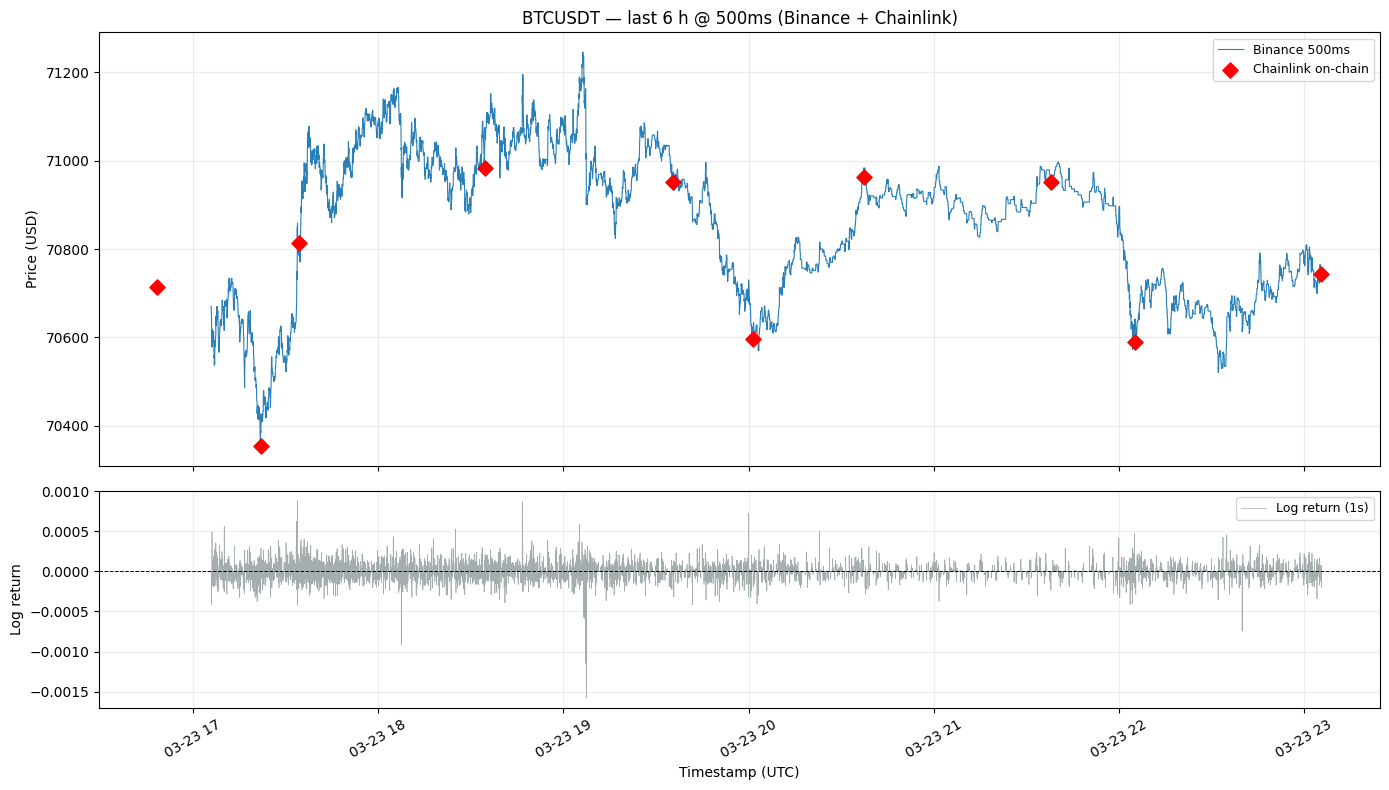

In [6]:
# ── Fetch ─────────────────────────────────────────────────────────────────────
print(f"Fetching Binance 1s klines  ({LOOKBACK_HOURS}h, {SYMBOL}) …")
klines_1s = fetch_binance_1s_klines(
    symbol=SYMBOL,
    lookback_minutes=LOOKBACK_MINUTES,
    binance_url=BINANCE_URL,
)
print(f"  → {len(klines_1s)} one-second candles")

print(f"Interpolating to {HALF_SEC_GRID} grid …")
btc_grid = interpolate_to_grid(klines_1s, grid_freq=HALF_SEC_GRID)
print(f"  → {len(btc_grid)} samples")

print("Fetching Chainlink on-chain rounds …")
chainlink_ref = fetch_chainlink_reference(
    lookback_minutes=LOOKBACK_MINUTES,
    rpc_url=ETH_RPC_URL,
    feed_address=CHAINLINK_FEED_ADDR,
    abi=CHAINLINK_ABI,
)
print(f"  → {len(chainlink_ref)} Chainlink round(s)")

# ── Compute log returns on the 1s series ─────────────────────────────────────
log_ret = np.log(klines_1s["close"]).diff()
log_ret_ts = klines_1s["timestamp"]

# ── Plot: price + log returns ─────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 8),
                         gridspec_kw={"height_ratios": [3, 1.5]},
                         sharex=True)

# Top: price
axes[0].plot(btc_grid["timestamp"], btc_grid["price_usd"],
             linewidth=0.8, color="#2980b9", label=f"Binance {HALF_SEC_GRID}")
axes[0].scatter(chainlink_ref["updated_at"], chainlink_ref["price_usd"],
                color="red", s=60, zorder=5, marker="D", label="Chainlink on-chain")
axes[0].set_title(f"{SYMBOL} — last {LOOKBACK_HOURS} h @ {HALF_SEC_GRID} (Binance + Chainlink)")
axes[0].set_ylabel("Price (USD)")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25)

# Bottom: log returns (bar if short window, line otherwise)
axes[1].plot(log_ret_ts, log_ret, linewidth=0.5, color="#7f8c8d", alpha=0.7, label="Log return (1s)")
axes[1].axhline(0, color="black", linewidth=0.7, linestyle="--")
axes[1].set_ylabel("Log return")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.2)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

15min windows : 5
Vol range : 22.0% – 34.6%
Vol mean  : 27.7%
(BTC typical: 40–80% normal | >80% elevated | <30% very quiet)



'                   window  vol_pct  n_ticks\n2026-03-23 22:00:00+00:00    26.74      601\n2026-03-23 22:15:00+00:00    21.97      900\n2026-03-23 22:30:00+00:00    32.04      900\n2026-03-23 22:45:00+00:00    22.97      900\n2026-03-23 23:00:00+00:00    34.62      299'

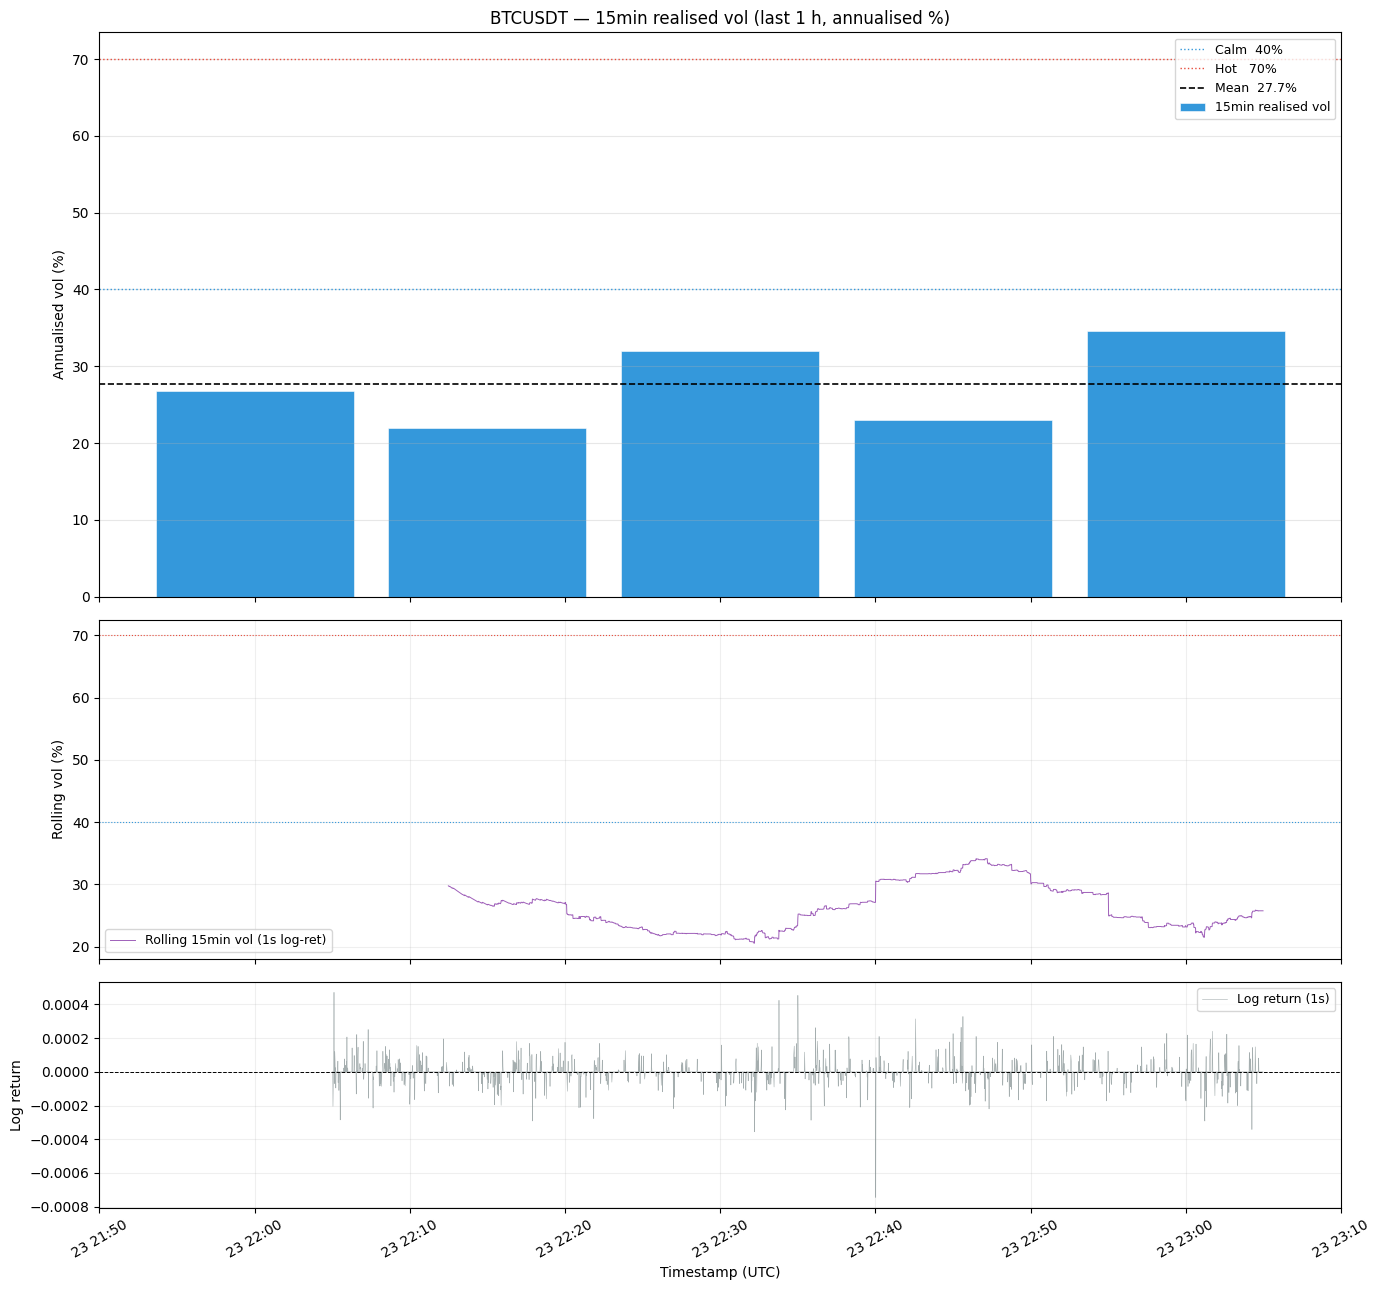

,window,vol_pct,n_ticks
0,2026-03-23 22:00:00+00:00,26.74,601
1,2026-03-23 22:15:00+00:00,21.97,900
2,2026-03-23 22:30:00+00:00,32.04,900
3,2026-03-23 22:45:00+00:00,22.97,900
4,2026-03-23 23:00:00+00:00,34.62,299


In [3]:
# ── Realised vol ─────────────────────────────────────────────────────────────
vol_df = realized_vol(
    klines_1s=klines_1s,
    vol_window=VOL_WINDOW,
    annualise_factor=ANNUALISE_1S,
)

print(f"{VOL_WINDOW} windows : {len(vol_df)}")
print(f"Vol range : {vol_df['vol_pct'].min():.1f}% – {vol_df['vol_pct'].max():.1f}%")
print(f"Vol mean  : {vol_df['vol_pct'].mean():.1f}%")
print(f"(BTC typical: 40–80% normal | >80% elevated | <30% very quiet)\n")
display(vol_df.to_string(index=False))

# ── Plot ──────────────────────────────────────────────────────────────────────
def _bar_color(v, calm, hot):
    if v >= hot:   return "#e74c3c"
    if v >= calm:  return "#f39c12"
    return "#3498db"

bar_colors  = [_bar_color(v, VOL_CALM_PCT, VOL_HOT_PCT) for v in vol_df["vol_pct"]]
bar_width   = pd.Timedelta(VOL_WINDOW) * 0.85

# ── 15-min log return: ln(last_close / first_close) per calendar bucket ───────
tmp = klines_1s.copy()
tmp["window"] = pd.to_datetime(tmp["timestamp"]).dt.floor(VOL_WINDOW)
window_log_ret = (
    tmp.groupby("window")["close"]
    .agg(first="first", last="last")
    .assign(log_ret=lambda d: np.log(d["last"] / d["first"]))
    .reset_index()
)

# Colour: green = positive return, red = negative
ret_colors = ["#27ae60" if r >= 0 else "#e74c3c" for r in window_log_ret["log_ret"]]

# ── Rolling vol (continuous, from 1s log-returns) ────────────────────────────
log_ret_1s   = np.log(klines_1s["close"]).diff()
window_secs  = int(pd.Timedelta(VOL_WINDOW).total_seconds())
roll_vol_pct = (
    log_ret_1s
    .rolling(window=window_secs, min_periods=window_secs // 2)
    .std()
    .mul(ANNUALISE_1S * 100)
)

fig, axes = plt.subplots(3, 1, figsize=(14, 13),
                         gridspec_kw={"height_ratios": [2.5, 1.5, 1.5]})

# ── Top: realised vol bars ────────────────────────────────────────────────────
ax0 = axes[0]
ax0.bar(vol_df["window"], vol_df["vol_pct"], width=bar_width,
        color=bar_colors, edgecolor="white", linewidth=0.4, label=f"{VOL_WINDOW} realised vol")
ax0.axhline(VOL_CALM_PCT, color="#3498db", linestyle=":", linewidth=1, label=f"Calm  {VOL_CALM_PCT}%")
ax0.axhline(VOL_HOT_PCT,  color="#e74c3c", linestyle=":", linewidth=1, label=f"Hot   {VOL_HOT_PCT}%")
ax0.axhline(vol_df["vol_pct"].mean(), color="black", linestyle="--", linewidth=1.2,
            label=f"Mean  {vol_df['vol_pct'].mean():.1f}%")
ax0.set_title(f"{SYMBOL} — {VOL_WINDOW} realised vol (last {LOOKBACK_HOURS} h, annualised %)")
ax0.set_ylabel("Annualised vol (%)")
ax0.legend(fontsize=9)
ax0.grid(axis="y", alpha=0.3)
ax0.set_xticks(vol_df["window"])
ax0.set_xticklabels([t.strftime("%H:%M") for t in vol_df["window"]], rotation=60, ha="right")

# ── Middle: rolling vol line ──────────────────────────────────────────────────
ax1 = axes[1]
ax1.plot(klines_1s["timestamp"], roll_vol_pct,
         linewidth=0.8, color="#8e44ad", alpha=0.85, label=f"Rolling {VOL_WINDOW} vol (1s)")
ax1.axhline(VOL_CALM_PCT, color="#3498db", linestyle=":", linewidth=0.8)
ax1.axhline(VOL_HOT_PCT,  color="#e74c3c", linestyle=":", linewidth=0.8)
ax1.set_ylabel("Rolling vol (%)")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.2)

# ── Bottom: 15-min log returns ────────────────────────────────────────────────
ax2 = axes[2]
ax2.bar(window_log_ret["window"], window_log_ret["log_ret"] * 100,
        width=bar_width, color=ret_colors, edgecolor="white", linewidth=0.4,
        label=f"{VOL_WINDOW} log return (%)")
ax2.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax2.set_ylabel("Log return (%)")
ax2.set_xlabel("Window start (UTC)")
ax2.legend(fontsize=9)
ax2.grid(axis="y", alpha=0.2)
ax2.set_xticks(window_log_ret["window"])
ax2.set_xticklabels([t.strftime("%H:%M") for t in window_log_ret["window"]], rotation=60, ha="right")

plt.tight_layout()
plt.show()

vol_df.merge(window_log_ret[["window", "log_ret"]], on="window")

In [ ]:
# ── Load pre-collected historical data ────────────────────────────────────────
# Run  `python btc_collector.py`  once from the terminal first.
# Then use this cell instead of fetch_binance_1s_klines() for big date ranges.

import sys
sys.path.insert(0, str(__import__("pathlib").Path("__file__").parent))
from btc_collector import load_btc_price

# Load everything saved (last 4 months, 0.5s grid by default)
# btc_hist = load_btc_price()

# Slice to a specific date range

# btc_hist = load_btc_price(start="2025-11-21", end="2026-03-22")
# Keep 1-second resolution instead of 0.5s
# btc_hist = load_btc_price(grid_freq="1s")

print("Uncomment a line above and run to load stored data.")

In [ ]:
# from btc_collector import load_btc_price

# START_DATE = "2025-11-21"
# END_DATE = "2026-03-22"

# klines_1s = load_btc_price(grid_freq="1s", start=START_DATE, end=END_DATE)
# btc_grid = interpolate_to_grid(klines_1s, grid_freq=HALF_SEC_GRID)

# vol_df = realized_vol(
#     klines_1s=klines_1s,
#     vol_window=VOL_WINDOW,
#     annualise_factor=ANNUALISE_1S,
# )

Loaded 10,454,400 raw 1s rows from 121 files — interpolating to 1s …
  → 10,454,401 1s samples  (2025-11-21 00:00:00+00:00  →  2026-03-22 00:00:00+00:00)


Loaded 10,454,401 1s rows and 20,908,802 500ms rows


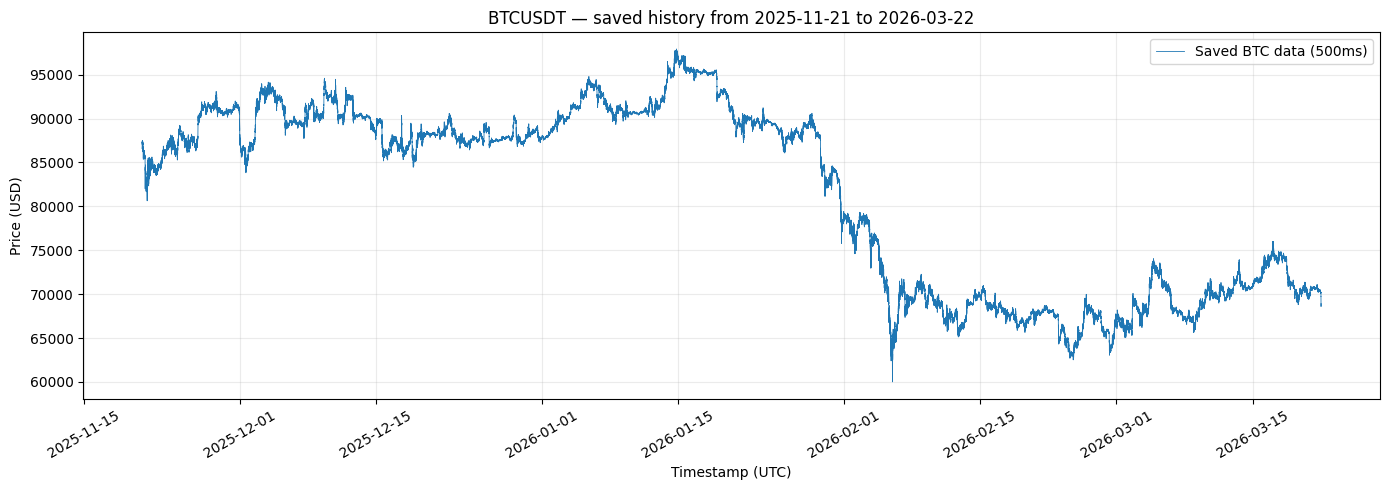

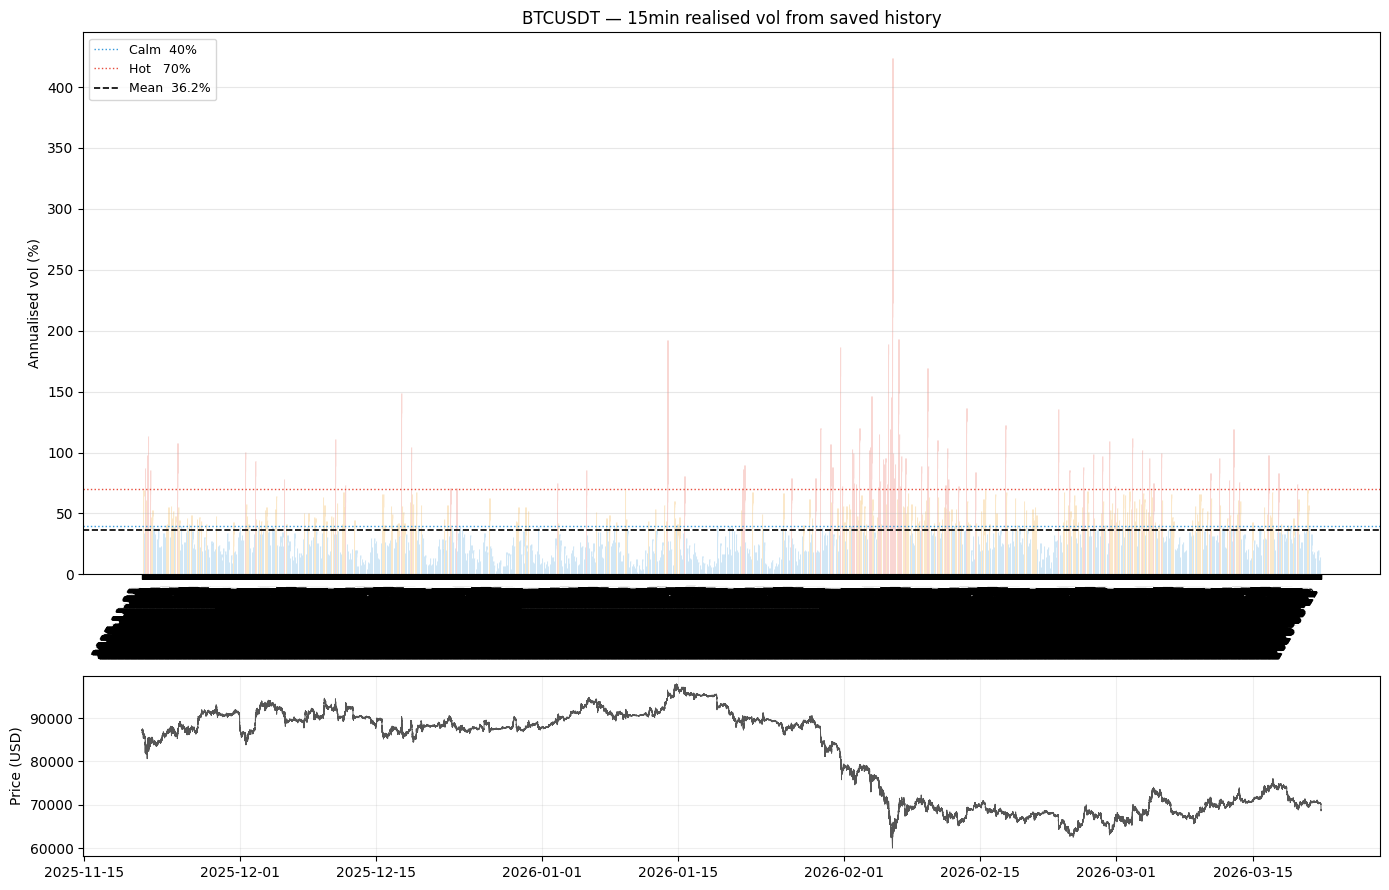

,window,vol_pct,n_ticks
11612,2026-03-21 23:00:00+00:00,20.80,900
11613,2026-03-21 23:15:00+00:00,15.92,900
11614,2026-03-21 23:30:00+00:00,15.00,900
11615,2026-03-21 23:45:00+00:00,157.76,900
11616,2026-03-22 00:00:00+00:00,NaN,1


In [ ]:
# Plot the loaded saved data
# print(f"Loaded {len(klines_1s):,} 1s rows and {len(btc_grid):,} {HALF_SEC_GRID} rows")

# fig, ax = plt.subplots(figsize=(14, 5))
# ax.plot(
#     btc_grid["timestamp"],
#     btc_grid["price_usd"],
#     linewidth=0.6,
#     label=f"Saved BTC data ({HALF_SEC_GRID})",
# )
# ax.set_title(f"{SYMBOL} — saved history from {START_DATE} to {END_DATE}")
# ax.set_xlabel("Timestamp (UTC)")
# ax.set_ylabel("Price (USD)")
# ax.legend()
# ax.grid(alpha=0.25)
# plt.xticks(rotation=30)
# plt.tight_layout()
# plt.show()


# def _bar_color_saved(v, calm, hot):
#     if v >= hot:
#         return "#e74c3c"
#     if v >= calm:
#         return "#f39c12"
#     return "#3498db"


# bar_colors = [_bar_color_saved(v, VOL_CALM_PCT, VOL_HOT_PCT) for v in vol_df["vol_pct"]]
# bar_width = pd.Timedelta(VOL_WINDOW) * 0.85

# fig, axes = plt.subplots(2, 1, figsize=(14, 9), gridspec_kw={"height_ratios": [3, 1]})

# ax = axes[0]
# ax.bar(vol_df["window"], vol_df["vol_pct"], width=bar_width,
#        color=bar_colors, edgecolor="white", linewidth=0.4)
# ax.axhline(VOL_CALM_PCT, color="#3498db", linestyle=":", linewidth=1,
#            label=f"Calm  {VOL_CALM_PCT}%")
# ax.axhline(VOL_HOT_PCT, color="#e74c3c", linestyle=":", linewidth=1,
#            label=f"Hot   {VOL_HOT_PCT}%")
# ax.axhline(vol_df["vol_pct"].mean(), color="black", linestyle="--", linewidth=1.2,
#            label=f"Mean  {vol_df['vol_pct'].mean():.1f}%")
# ax.set_title(f"{SYMBOL} — {VOL_WINDOW} realised vol from saved history")
# ax.set_ylabel("Annualised vol (%)")
# ax.legend(fontsize=9)
# ax.grid(axis="y", alpha=0.3)
# ax.set_xticks(vol_df["window"])
# ax.set_xticklabels([t.strftime("%Y-%m-%d") for t in vol_df["window"]], rotation=60, ha="right")

# axes[1].plot(klines_1s["timestamp"], klines_1s["close"], linewidth=0.7, color="#555")
# axes[1].set_ylabel("Price (USD)")
# axes[1].grid(alpha=0.2)

# plt.tight_layout()
# plt.show()

# vol_df.tail()